<a href="https://colab.research.google.com/github/Arisha-biotech/Single-Cell-RNA-Seq-COVID19-Lung-Atlas/blob/main/COVID19_Lung_scRNA_Seq.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
!wget "https://ftp.ncbi.nlm.nih.gov/geo/series/GSE171nnn/GSE171524/suppl/GSE171524%5FRAW%2Etar"

!mkdir -p raw_counts
!tar -xvf GSE171524_RAW.tar -C raw_counts/

!gunzip raw_counts/*.gz


--2026-11-19 05:26:05--  https://ftp.ncbi.nlm.nih.gov/geo/series/GSE171nnn/GSE171524/suppl/GSE171524%5FRAW%2Etar
Resolving ftp.ncbi.nlm.nih.gov (ftp.ncbi.nlm.nih.gov)... 130.14.250.7, 130.14.250.10, 2607:f220:41e:250::12, ...
Connecting to ftp.ncbi.nlm.nih.gov (ftp.ncbi.nlm.nih.gov)|130.14.250.7|:443... connected.
HTTP request sent, awaiting response... 200 OK
Length: 169728000 (162M) [application/x-tar]
Saving to: ‘GSE171524_RAW.tar’

GSE171524_RAW.tar   100%[===================>] 161.87M  5.07MB/s    in 35s     

2026-11-19 05:26:42 (4.60 MB/s) - ‘GSE171524_RAW.tar’ saved [169728000/169728000]

GSM5226574_C51ctr_raw_counts.csv.gz
GSM5226575_C52ctr_raw_counts.csv.gz
GSM5226576_C53ctr_raw_counts.csv.gz
GSM5226577_C54ctr_raw_counts.csv.gz
GSM5226578_C55ctr_raw_counts.csv.gz
GSM5226579_C56ctr_raw_counts.csv.gz
GSM5226580_C57ctr_raw_counts.csv.gz
GSM5226581_L01cov_raw_counts.csv.gz
GSM5226582_L03cov_raw_counts.csv.gz
GSM5226583_L04cov_raw_counts.csv.gz
GSM5226584_L04covaddon_raw_counts.cs

In [2]:
!pip install -q scvi-tools scikit-misc
!pip install scanpy
import scanpy as sc
adata= sc.read_csv('raw_counts/GSM5226574_C51ctr_raw_counts.csv').T
adata

  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done
ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
google-colab 1.0.0 requires pandas==2.2.3, but you have pandas 3.1.1 which is incompatible.
cudf-cu13 26.6.0 requires pandas<2.4.0,>=2.0, but you have pandas 3.1.1 which is incompatible.
dask-cudf-cu13 26.6.0 requires pandas<2.4.0,>=2.0, but you have pandas 3.1.1 which is incompatible.


/usr/local/lib/python3.13/dist-packages/pandas/core/arrays/arrow/__init__.py:5: UserWarning: Pandas requires version '1.5.0' or newer of 'bottleneck' (version '1.4.2' currently installed).
  from pandas.core.arrays.arrow.array import ArrowExtensionArray
/tmp/ipykernel_323/3515663174.py:4: FutureWarning: Import from `scanpy.io` instead
  adata= sc.read_csv('raw_counts/GSM5226574_C51ctr_raw_counts.csv').T


AnnData object with n_obs × n_vars = 6099 × 34546
    layers: None (.X)

In [3]:
import scvi

sc.pp.filter_genes(adata, min_cells = 10)
sc.pp.highly_variable_genes(adata, n_top_genes = 2000, subset = True, flavor = 'seurat_v3')

scvi.model.SCVI.setup_anndata(adata)
vae = scvi.model.SCVI(adata)
vae.train()

solo = scvi.external.SOLO.from_scvi_model(vae)
solo.train()

df = solo.predict()
df['prediction'] = solo.predict(soft = False)
df['dif'] = df.doublet - df.singlet
doublets = df[(df.prediction == 'doublet') & (df.dif > 1)]


INFO: GPU available: True (cuda), used: True
INFO:lightning.pytorch.utilities.rank_zero:GPU available: True (cuda), used: True
INFO: TPU available: False, using: 0 TPU cores
INFO:lightning.pytorch.utilities.rank_zero:TPU available: False, using: 0 TPU cores
INFO: 💡 Tip: For seamless cloud logging and experiment tracking, try installing [litlogger](https://pypi.org/project/litlogger/) to enable LitLogger, which logs metrics and artifacts automatically to the Lightning Experiments platform.
INFO:lightning.pytorch.utilities.rank_zero:💡 Tip: For seamless cloud logging and experiment tracking, try installing [litlogger](https://pypi.org/project/litlogger/) to enable LitLogger, which logs metrics and artifacts automatically to the Lightning Experiments platform.
INFO: LOCAL_RANK: 0 - CUDA_VISIBLE_DEVICES: [0]
INFO:lightning.pytorch.accelerators.cuda:LOCAL_RANK: 0 - CUDA_VISIBLE_DEVICES: [0]
/usr/local/lib/python3.13/dist-packages/lightning/pytorch/utilities/_pytree.py:21: `isinstance(treespe

Training:   0%|          | 0/400 [00:00<?, ?it/s]

INFO: `Trainer.fit` stopped: `max_epochs=400` reached.
INFO:lightning.pytorch.utilities.rank_zero:`Trainer.fit` stopped: `max_epochs=400` reached.


INFO     Creating doublets, preparing SOLO model.                                                                  


INFO: GPU available: True (cuda), used: True
INFO:lightning.pytorch.utilities.rank_zero:GPU available: True (cuda), used: True
INFO: TPU available: False, using: 0 TPU cores
INFO:lightning.pytorch.utilities.rank_zero:TPU available: False, using: 0 TPU cores
INFO: 💡 Tip: For seamless cloud logging and experiment tracking, try installing [litlogger](https://pypi.org/project/litlogger/) to enable LitLogger, which logs metrics and artifacts automatically to the Lightning Experiments platform.
INFO:lightning.pytorch.utilities.rank_zero:💡 Tip: For seamless cloud logging and experiment tracking, try installing [litlogger](https://pypi.org/project/litlogger/) to enable LitLogger, which logs metrics and artifacts automatically to the Lightning Experiments platform.
INFO: LOCAL_RANK: 0 - CUDA_VISIBLE_DEVICES: [0]
INFO:lightning.pytorch.accelerators.cuda:LOCAL_RANK: 0 - CUDA_VISIBLE_DEVICES: [0]
/usr/local/lib/python3.13/dist-packages/lightning/pytorch/utilities/_pytree.py:21: `isinstance(treespe

Training:   0%|          | 0/400 [00:00<?, ?it/s]

Monitored metric validation_loss did not improve in the last 30 records. Best score: 0.283. Signaling Trainer to stop.


/usr/local/lib/python3.13/dist-packages/torch/utils/_contextlib.py:124: UserWarning: Prior to scvi-tools 1.1.3, `SOLO.predict` with `soft=True` (the default option) returned logits instead of probabilities. This behavior has since been corrected to return probabilities. The previous behavior can be replicated by passing in `return_logits=True`.
  return func(*args, **kwargs)


In [4]:
import numpy as np
import pandas as pd

ribo_url = "http://broadinstitute.org"
ribo_genes = pd.read_table(ribo_url, skiprows=2, header=None)

adata = sc.read_csv('raw_counts/GSM5226574_C51ctr_raw_counts.csv').T
adata.obs['doublet'] = adata.obs.index.isin(doublets.index)
adata = adata[~adata.obs.doublet]

adata.var['mt'] = adata.var.index.str.startswith('MT-')
adata.var['ribo'] = adata.var_names.isin(ribo_genes[0].values)

sc.pp.calculate_qc_metrics(adata, qc_vars=['mt', 'ribo'], percent_top=None, log1p=False, inplace=True)

sc.pp.filter_genes(adata, min_cells=3)
upper_lim = np.quantile(adata.obs.n_genes_by_counts.values, .98)
adata = adata[adata.obs.n_genes_by_counts < upper_lim]
adata = adata[adata.obs.pct_counts_mt < 20]
adata = adata[adata.obs.pct_counts_ribo < 2]

print(f"Doublets removed: {len(doublets)}")
adata


/tmp/ipykernel_323/3688540830.py:7: FutureWarning: Import from `scanpy.io` instead
  adata = sc.read_csv('raw_counts/GSM5226574_C51ctr_raw_counts.csv').T
/tmp/ipykernel_323/3688540830.py:11: ImplicitModificationWarning: Trying to modify attribute `.var` of view, initializing view as actual.
  adata.var['mt'] = adata.var.index.str.startswith('MT-')
/tmp/ipykernel_323/3688540830.py:14: FutureWarning: The argument inplace is deprecated and will be removed in the future. Use `out=False` instead of `inplace=True`.
  sc.pp.calculate_qc_metrics(adata, qc_vars=['mt', 'ribo'], percent_top=None, log1p=False, inplace=True)


Doublets removed: 0


View of AnnData object with n_obs × n_vars = 5977 × 24660
    obs: 'doublet', 'n_genes_by_counts', 'total_counts', 'total_counts_mt', 'pct_counts_mt', 'total_counts_ribo', 'pct_counts_ribo'
    var: 'mt', 'ribo', 'n_cells_by_counts', 'mean_counts', 'pct_dropout_by_counts', 'total_counts', 'n_cells'
    layers: None (.X)

In [5]:
sc.pp.normalize_total(adata, target_sum=1e4)
sc.pp.log1p(adata)
adata.raw = adata


/usr/local/lib/python3.13/dist-packages/scverse_misc/_deprecated/__init__.py:117: UserWarning: Received a view of an AnnData. Making a copy.
  return func(*args, **kwargs)


/usr/local/lib/python3.13/dist-packages/scverse_misc/_deprecated/__init__.py:117: UserWarning: Received a view of an AnnData. Making a copy.
  return func(*args, **kwargs)
/usr/local/lib/python3.13/dist-packages/scverse_misc/_deprecated/__init__.py:117: FutureWarning: The `igraph` and `networkit` implementations of leiden clustering are *orders of magnitude faster*. Set the flavor argument to (and install if needed) 'igraph' or 'networkit' to use them.
In the future, the default backend for leiden will be igraph instead of leidenalg. To achieve the future defaults please pass: `flavor='igraph'` and `n_iterations=2`.
  return func(*args, **kwargs)


leiden
0     1262
1      809
2      804
3      690
4      450
5      356
6      267
7      263
8      225
9      153
10     134
11     119
12      93
13      74
14      62
15      56
16      50
17      35
18      31
19      25
20      19
Name: count, dtype: int64


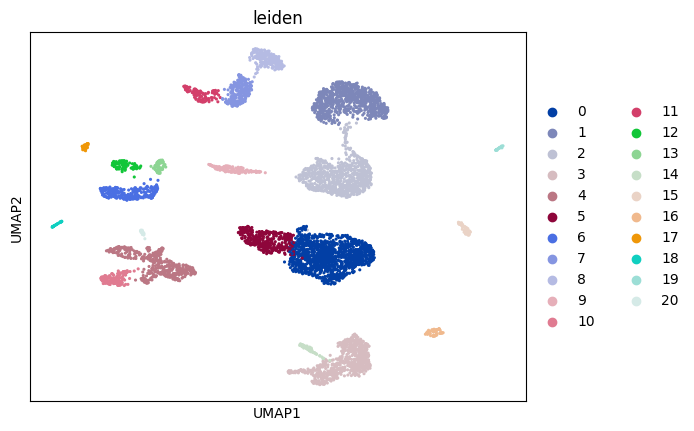

In [6]:
!pip install -q leidenalg
sc.pp.highly_variable_genes(adata, n_top_genes = 2000)
adata = adata[:, adata.var.highly_variable]

sc.pp.regress_out(adata, ['total_counts', 'pct_counts_mt', 'pct_counts_ribo'])
sc.pp.scale(adata, max_value=10)

sc.tl.pca(adata, svd_solver='arpack')
sc.pp.neighbors(adata, n_pcs = 30)
sc.tl.umap(adata)
sc.tl.leiden(adata, resolution = 0.5)

print(adata.obs['leiden'].value_counts())
sc.pl.umap(adata, color=['leiden'])


In [7]:
import os

!pip install -q scanpy scvi-tools scikit-misc leidenalg


if not os.path.exists('raw_counts') or len(os.listdir('raw_counts')) == 0:
    !wget -q "https://nih.gov"
    !mkdir -p raw_counts
    !tar -xf GSE171524_RAW.tar -C raw_counts/
    !gunzip -f raw_counts/*.gz

import gc
import numpy as np
import pandas as pd
import scanpy as sc
from scipy.sparse import csr_matrix


ribo_url = "http://broadinstitute.org"
ribo_genes = pd.read_table(ribo_url, skiprows=2, header=None)


def pp(csv_path):
    adata = sc.read_csv(csv_path).T
    adata.X = csr_matrix(adata.X)

    sample_name = os.path.basename(csv_path).split('_')[1]
    adata.obs['Sample'] = sample_name
    adata.obs['Condition'] = 'Control' if 'ctr' in sample_name.lower() else 'COVID-19'

    adata.var['mt'] = adata.var.index.str.startswith('MT-')
    adata.var['ribo'] = adata.var_names.isin(ribo_genes[0].values)
    sc.pp.calculate_qc_metrics(adata, qc_vars=['mt', 'ribo'], percent_top=None, log1p=False, inplace=True)

    upper_lim = np.quantile(adata.obs.n_genes_by_counts.values, .98)
    adata = adata[adata.obs.n_genes_by_counts < upper_lim].copy()
    adata = adata[adata.obs.pct_counts_mt < 20].copy()
    adata = adata[adata.obs.pct_counts_ribo < 2].copy()
    return adata


out = []
for f in sorted(os.listdir('raw_counts/')):
    if f.endswith('.csv'):
       out.append(pp('raw_counts/' + f))
       gc.collect()

adata = sc.concat(out)
del out
gc.collect()


sc.pp.filter_genes(adata, min_cells=10)
adata.layers['counts'] = adata.X.copy()
sc.pp.normalize_total(adata, target_sum=1e4)
sc.pp.log1p(adata)
adata.raw = adata



/tmp/ipykernel_323/2594299160.py:24: FutureWarning: Import from `scanpy.io` instead
  adata = sc.read_csv(csv_path).T
/tmp/ipykernel_323/2594299160.py:33: FutureWarning: The argument inplace is deprecated and will be removed in the future. Use `out=False` instead of `inplace=True`.
  sc.pp.calculate_qc_metrics(adata, qc_vars=['mt', 'ribo'], percent_top=None, log1p=False, inplace=True)
/tmp/ipykernel_323/2594299160.py:24: FutureWarning: Import from `scanpy.io` instead
  adata = sc.read_csv(csv_path).T
/tmp/ipykernel_323/2594299160.py:33: FutureWarning: The argument inplace is deprecated and will be removed in the future. Use `out=False` instead of `inplace=True`.
  sc.pp.calculate_qc_metrics(adata, qc_vars=['mt', 'ribo'], percent_top=None, log1p=False, inplace=True)
/tmp/ipykernel_323/2594299160.py:24: FutureWarning: Import from `scanpy.io` instead
  adata = sc.read_csv(csv_path).T
/tmp/ipykernel_323/2594299160.py:33: FutureWarning: The argument inplace is deprecated and will be removed

In [8]:
sc.pp.highly_variable_genes(adata, n_top_genes=2000, subset=True, batch_key='Sample')

print(adata)
print("\nCells per Condition:")
print(adata.obs['Condition'].value_counts())


/tmp/ipykernel_323/2855367638.py:1: FutureWarning: The argument batch_key is deprecated and will be removed in the future. Use `batch` instead, e.g. `batch=A.obs['b']` for `batch_key='b'`.
  sc.pp.highly_variable_genes(adata, n_top_genes=2000, subset=True, batch_key='Sample')


AnnData object with n_obs × n_vars = 113972 × 2000
    obs: 'Sample', 'Condition', 'n_genes_by_counts', 'total_counts', 'total_counts_mt', 'pct_counts_mt', 'total_counts_ribo', 'pct_counts_ribo'
    var: 'n_cells', 'highly_variable', 'means', 'dispersions', 'highly_variable_nbatches', 'highly_variable_intersection', 'dispersions_norm'
    uns: 'log1p', 'hvg'
    layers: None (.X), 'counts'

Cells per Condition:
Condition
COVID-19    78031
Control     35941
Name: count, dtype: int64


In [13]:
import scvi

# Training scVI batch integration across all 27 patient samples
scvi.model.SCVI.setup_anndata(
    adata,
    layer="counts",
    categorical_covariate_keys=["Sample"],
   continuous_covariate_keys=["pct_counts_mt", "total_counts", "pct_counts_ribo"]
)
model = scvi.model.SCVI(adata)
model.train(max_epochs=50, early_stopping=True)

# Saving the batch-corrected latent coordinates so the next cell can build the UMAP
adata.obsm["X_scVI"] = model.get_latent_representation()

INFO: GPU available: True (cuda), used: True
INFO:lightning.pytorch.utilities.rank_zero:GPU available: True (cuda), used: True
INFO: TPU available: False, using: 0 TPU cores
INFO:lightning.pytorch.utilities.rank_zero:TPU available: False, using: 0 TPU cores
INFO: 💡 Tip: For seamless cloud logging and experiment tracking, try installing [litlogger](https://pypi.org/project/litlogger/) to enable LitLogger, which logs metrics and artifacts automatically to the Lightning Experiments platform.
INFO:lightning.pytorch.utilities.rank_zero:💡 Tip: For seamless cloud logging and experiment tracking, try installing [litlogger](https://pypi.org/project/litlogger/) to enable LitLogger, which logs metrics and artifacts automatically to the Lightning Experiments platform.
INFO: LOCAL_RANK: 0 - CUDA_VISIBLE_DEVICES: [0]
INFO:lightning.pytorch.accelerators.cuda:LOCAL_RANK: 0 - CUDA_VISIBLE_DEVICES: [0]
/usr/local/lib/python3.13/dist-packages/lightning/pytorch/utilities/_pytree.py:21: `isinstance(treespe

Training:   0%|          | 0/50 [00:00<?, ?it/s]

/usr/local/lib/python3.13/dist-packages/torch/utils/data/_utils/collate.py:70: UserWarning: The given NumPy array is not writable, and PyTorch does not support non-writable tensors. This means writing to this tensor will result in undefined behavior. You may want to copy the array to protect its data or make it writable before converting it to a tensor. This type of warning will be suppressed for the rest of this program. (Triggered internally at /__w/pytorch/pytorch/torch/csrc/utils/tensor_numpy.cpp:213.)
  return torch.as_tensor(data)
INFO: `Trainer.fit` stopped: `max_epochs=50` reached.
INFO:lightning.pytorch.utilities.rank_zero:`Trainer.fit` stopped: `max_epochs=50` reached.


/tmp/ipykernel_323/2354022893.py:2: FutureWarning: The argument use_rep is deprecated and will be removed in the future. Use `use` instead.
  sc.pp.neighbors(adata, use_rep="X_scVI", transformer="sklearn")
/usr/local/lib/python3.13/dist-packages/scverse_misc/_deprecated/__init__.py:117: FutureWarning: The `igraph` and `networkit` implementations of leiden clustering are *orders of magnitude faster*. Set the flavor argument to (and install if needed) 'igraph' or 'networkit' to use them.
In the future, the default backend for leiden will be igraph instead of leidenalg. To achieve the future defaults please pass: `flavor='igraph'` and `n_iterations=2`.
  return func(*args, **kwargs)


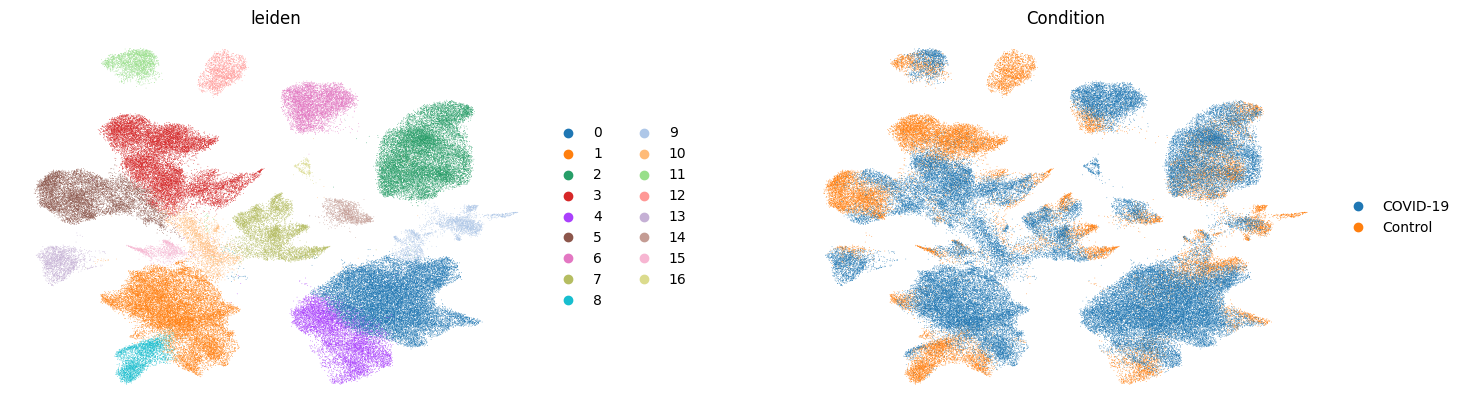

In [14]:
# Using sklearn transformer to bypass the numba 2-CPU thread crash completely!
sc.pp.neighbors(adata, use_rep="X_scVI", transformer="sklearn")
sc.tl.umap(adata)
sc.tl.leiden(adata, resolution=0.5)
# Drawing integrated UMAP plots
sc.pl.umap(adata, color=["leiden", "Condition"], wspace=0.35, frameon=False)


/tmp/ipykernel_323/3785613499.py:31: FutureWarning: The argument score_name is deprecated and will be removed in the future. Use `out` instead.
  sc.tl.score_genes(adata, valid_genes, score_name=cell_type, use_raw=True)
/tmp/ipykernel_323/3785613499.py:31: FutureWarning: The argument use_raw is deprecated and will be removed in the future. :attr:`~anndata.AnnData.raw` is deprecated. Keep the data in a layer instead.
  sc.tl.score_genes(adata, valid_genes, score_name=cell_type, use_raw=True)
/tmp/ipykernel_323/3785613499.py:31: FutureWarning: The argument score_name is deprecated and will be removed in the future. Use `out` instead.
  sc.tl.score_genes(adata, valid_genes, score_name=cell_type, use_raw=True)
/tmp/ipykernel_323/3785613499.py:31: FutureWarning: The argument use_raw is deprecated and will be removed in the future. :attr:`~anndata.AnnData.raw` is deprecated. Keep the data in a layer instead.
  sc.tl.score_genes(adata, valid_genes, score_name=cell_type, use_raw=True)
/tmp/ipy

/tmp/ipykernel_323/3785613499.py:38: FutureWarning: Argument `save` is deprecated and will be removed in a future version. Use `sc.pl.plot(show=False).figure.savefig()` instead.
  sc.pl.umap(


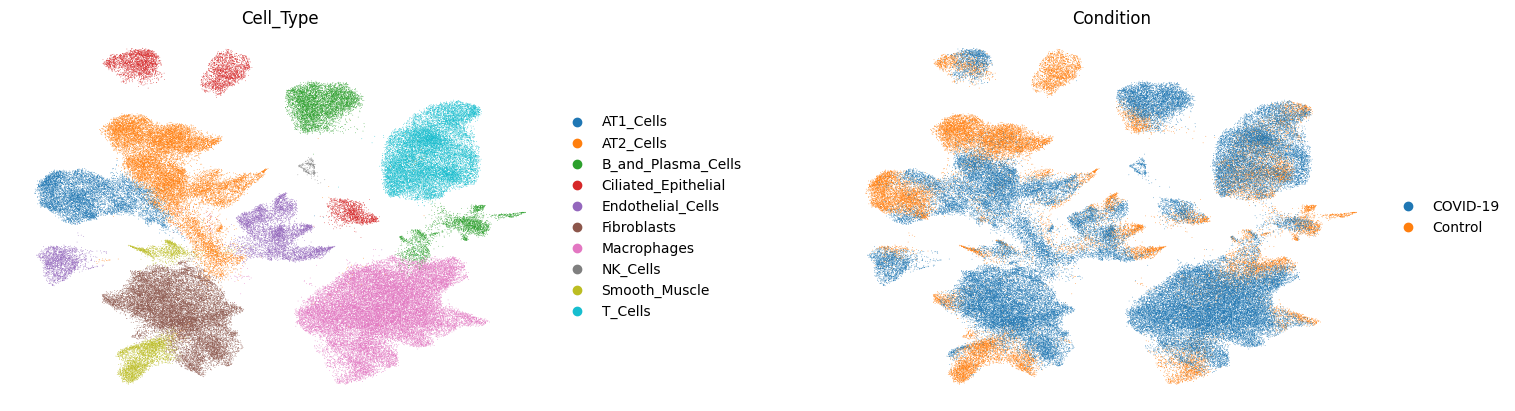

/tmp/ipykernel_323/3785613499.py:47: FutureWarning: Argument `save` is deprecated and will be removed in a future version. Use `sc.pl.plot(show=False).figure.savefig()` instead.
  sc.pl.dotplot(


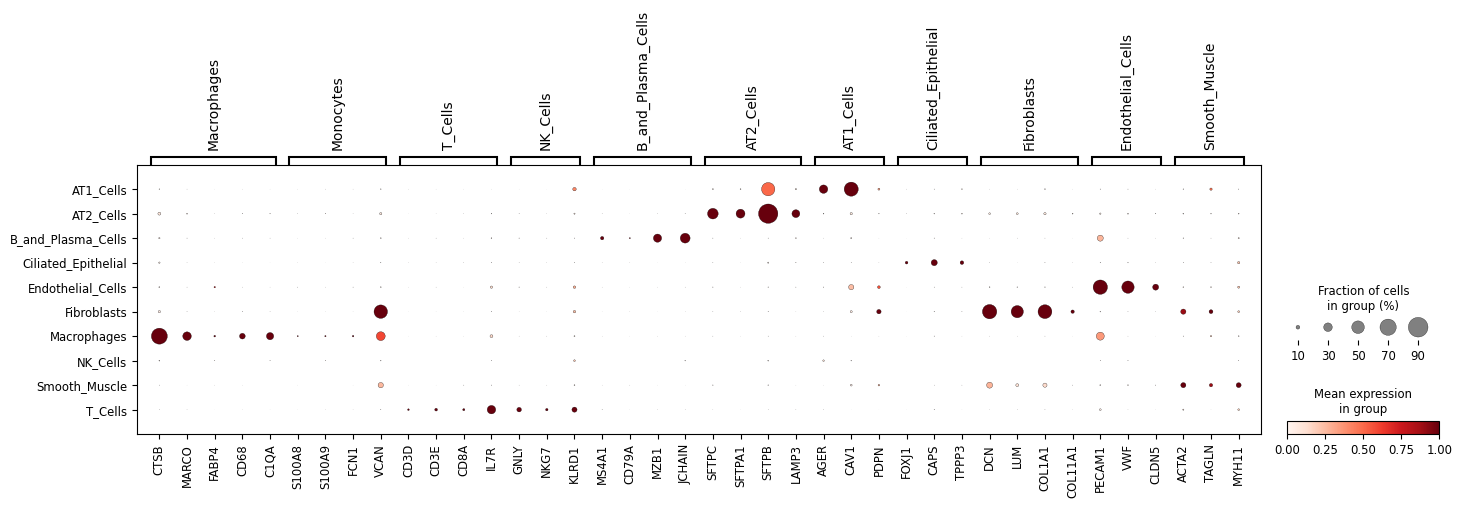

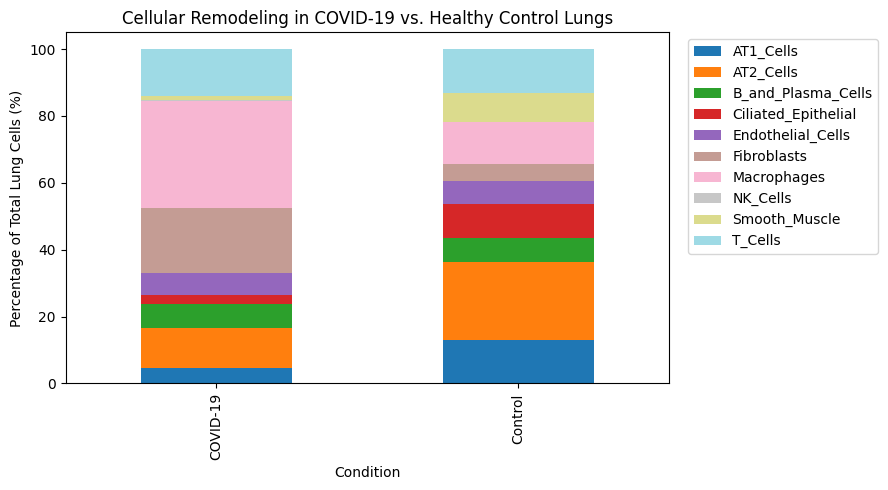

Project Complete! All figures and marker tables saved in the 'figures/' folder.


In [15]:
import os
import matplotlib.pyplot as plt

# 1. Creating a folder to save high-resolution figures for my GitHub README
os.makedirs("figures", exist_ok=True)
sc.settings.figdir = "figures"

# 2. Finding top marker genes for every cluster
sc.tl.rank_genes_groups(adata, groupby="leiden", method="wilcoxon")
markers = sc.get.rank_genes_groups_df(adata, None)
markers.to_csv("figures/top_cluster_markers.csv", index=False)

# 3. Automatically assign biological lung cell names using canonical marker genes
lung_markers = {
    "Macrophages": ["CTSB", "MARCO", "FABP4", "CD68", "C1QA"],
    "Monocytes": ["S100A8", "S100A9", "FCN1", "VCAN"],
    "T_Cells": ["CD3D", "CD3E", "CD8A", "IL7R"],
    "NK_Cells": ["GNLY", "NKG7", "KLRD1"],
    "B_and_Plasma_Cells": ["MS4A1", "CD79A", "MZB1", "JCHAIN"],
    "AT2_Cells": ["SFTPC", "SFTPA1", "SFTPB", "LAMP3"],
    "AT1_Cells": ["AGER", "CAV1", "PDPN"],
    "Ciliated_Epithelial": ["FOXJ1", "CAPS", "TPPP3"],
    "Fibroblasts": ["DCN", "LUM", "COL1A1", "COL11A1"],
    "Endothelial_Cells": ["PECAM1", "VWF", "CLDN5"],
    "Smooth_Muscle": ["ACTA2", "TAGLN", "MYH11"]
}

# Score each cell for canonical lung signatures and label each cluster by its top biological match
for cell_type, genes in lung_markers.items():
    valid_genes = [g for g in genes if g in adata.raw.var_names]
    sc.tl.score_genes(adata, valid_genes, score_name=cell_type, use_raw=True)

cluster_scores = adata.obs.groupby("leiden", observed=False)[list(lung_markers.keys())].mean()
cluster_to_celltype = cluster_scores.idxmax(axis=1).to_dict()
adata.obs["Cell_Type"] = adata.obs["leiden"].map(cluster_to_celltype)

# 4. Save Figure 1: Annotated Lung Cell Atlas & COVID-19 vs Control UMAP
sc.pl.umap(
    adata,
    color=["Cell_Type", "Condition"],
    wspace=0.4,
    frameon=False,
    save="_annotated_covid19_lung_atlas.png"
)

# 5. Save Figure 2: Canonical Marker Gene Dot Plot
sc.pl.dotplot(
    adata,
    var_names=lung_markers,
    groupby="Cell_Type",
    standard_scale="var",
    save="_lung_celltype_markers.png"
)

# 6. Save Figure 3: Cell Type Proportions in Control vs COVID-19 Lungs
ct_counts = pd.crosstab(adata.obs["Condition"], adata.obs["Cell_Type"], normalize="index") * 100
ax = ct_counts.plot(kind="bar", stacked=True, figsize=(9, 5), colormap="tab20")
plt.ylabel("Percentage of Total Lung Cells (%)")
plt.title("Cellular Remodeling in COVID-19 vs. Healthy Control Lungs")
plt.legend(bbox_to_anchor=(1.02, 1), loc="upper left")
plt.tight_layout()
plt.savefig("figures/condition_cell_proportions.png", dpi=300)
plt.show()

print("Project Complete! All figures and marker tables saved in the 'figures/' folder.")

In [16]:
!zip -r figures.zip figures/


  adding: figures/ (stored 0%)
  adding: figures/top_cluster_markers.csv (deflated 66%)
  adding: figures/dotplot__lung_celltype_markers.png (deflated 11%)
  adding: figures/umap_annotated_covid19_lung_atlas.png (deflated 0%)
  adding: figures/condition_cell_proportions.png (deflated 21%)
